In [79]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [80]:
df = pd.read_csv('loan.csv')

df

,age,gender,occupation,education_level,marital_status,income,credit_score,loan_status
0,32,Male,Engineer,Bachelor's,Married,85000,720,Approved
1,45,Female,Teacher,Master's,Single,62000,680,Approved
2,28,Male,Student,High School,Single,25000,590,Denied
3,51,Female,Manager,Bachelor's,Married,105000,780,Approved
4,36,Male,Accountant,Bachelor's,Married,75000,710,Approved
...,...,...,...,...,...,...,...,...
56,39,Male,Architect,Master's,Married,100000,770,Approved
57,25,Female,Receptionist,High School,Single,32000,570,Denied
58,43,Male,Banker,Bachelor's,Married,95000,760,Approved
59,30,Female,Writer,Master's,Single,55000,650,Approved


1.Get basic averages 

In [81]:
print("Average Income:", df['income'].mean())
print("Average Credit Score:", df['credit_score'].mean())

Average Income: 78983.60655737705
Average Credit Score: 709.8360655737705


Task 2: Filter for High Income ApplicantsWrite a simple condition to see only applicants earning over $\$80,000$:

In [82]:
#Filter for high income over 80k
high_earners = df[df['income'] > 80000]

#Display the top 5 high earners 
print(high_earners.head())

   age  gender occupation education_level marital_status  income  \
0   32    Male   Engineer      Bachelor's        Married   85000   
3   51  Female    Manager      Bachelor's        Married  105000   
6   42    Male     Lawyer        Doctoral        Married  120000   
8   37    Male         IT        Master's        Married   92000   
9   48  Female     Doctor        Doctoral        Married  180000   

   credit_score loan_status  
0           720    Approved  
3           780    Approved  
6           790    Approved  
8           750    Approved  
9           820    Approved  


Task 3 : Count Approved VS Denied loans 

Use .value_counts() to see how many people were approved vs. denied:

In [83]:
#Count totals for loan status 
print(df['loan_status'].value_counts())

loan_status
Approved    45
Denied      16
Name: count, dtype: int64


Task 4: Compare Income by Loan Status

Group the data by loan_status to compare the average income of approved applicants versus denied applicants:

In [84]:
# Compare average income 
print(df.groupby('loan_status')['income'].mean())

loan_status
Approved    92955.555556
Denied      39687.500000
Name: income, dtype: float64


Task 5: Calculate Approval Rate as a Percentage
Instead of just counting approved vs. denied, calculate the exact percentage of approved loans.

In [85]:
#Calculate total rows 
total_applicants = len(df)

#Count approved loans 
approved_count = (df['loan_status'] == 'Approved').sum()

#Calculate percentage 
approval_rate = (approved_count / total_applicants) * 100
print("approval_rate:", round(approval_rate, 2), "%")

approval_rate: 73.77 %


Task 6: Filter with Multiple Conditions
Find applicants who are both Single AND have a credit score above 700.

In [86]:
# Use & for AND, | for OR. Always wrap conditions in parentheses!
single_high_credit = df[(df['marital_status'] == 'Single') & (df['credit_score'] > 700)]

print(single_high_credit[['age', 'income', 'credit_score', 'loan_status']])

    age  income  credit_score loan_status
25   28   75000           710    Approved


Task 7: Group By and Aggregate Multiple Metrics
Group the data by education_level and see the average income and average credit score for each group in one table.

In [87]:
#Group by education level and calculate mean for mutiple columns
education_summary = df.groupby('education_level')[['income', 'credit_score']].mean()
print(education_summary)

                        income  credit_score
education_level                             
Associate's       50833.333333    651.666667
Bachelor's        72347.826087    703.043478
Doctoral         127300.000000    796.000000
High School       37428.571429    601.428571
Master's          87600.000000    736.666667


Task 8: Find the Minimum and Maximum for Approved Applicants
Check the financial boundaries for people who got approved.

In [88]:
#Filter for approved loans 
approved_df = df[df['loan_status'] == 'Approved']

#Get min and max credit scores 
print("Lowest Approved Credit Score: ", approved_df['credit_score'].min())
print("Highest Approved credit Score: ", approved_df['credit_score'].max())
print("Lowest Approved income: ", approved_df['income'].min())

Lowest Approved Credit Score:  650
Highest Approved credit Score:  830
Lowest Approved income:  55000


Task 9: Create a Debt-to-Income / Credit-to-Income Ratio Column
Create a new column called credit_to_income that measures how much credit score an applicant has relative to their income.

In [89]:
#Create a new column by dividing two existing columns 
df['credit_to_income'] = df['credit_score'] / df['income']

#display the first 5 rows with the new column 
print(df[['income', 'credit_score', 'credit_to_income', 'loan_status']].head())

   income  credit_score  credit_to_income loan_status
0   85000           720          0.008471    Approved
1   62000           680          0.010968    Approved
2   25000           590          0.023600      Denied
3  105000           780          0.007429    Approved
4   75000           710          0.009467    Approved


Task 10: Categorise Applicants into Income Brackets using pd.cut()
Instead of looking at exact income numbers, group applicants into 3 simple buckets: Low, Medium, and High.

In [90]:
#Define bin boundaries and labels 
bins = [0, 50000, 90000 , 200000]
labels = ['Low', 'Medium', 'High']

#Create the income_bracket column 
df['income_bracket'] = pd.cut(df['income'], bins=bins, labels=labels)

#check how many applicants fall into each bracket 
print(df['income_bracket'].value_counts())

income_bracket
Medium    25
High      21
Low       15
Name: count, dtype: int64


Task 11: Create a Risk Flag Column with Conditional Logic (np.select)
Combine multiple columns to create a custom risk_tier flag (Low Risk, Medium Risk, High Risk).

In [91]:
import numpy as np 

# define conditions 
conditions = [
    (df['credit_score'] >= 720) & (df['income'] >= 75000), #low risk
    (df['credit_score'] >= 650) & (df['income'] >= 53500) #medium risk
]

#define corresponding outputs 
choices = ['Low Risk', 'Medium Risk']

#create the new column (defaulting to 'high risk')
df['risk_tier'] = np.select(conditions, choices, default="High Risk")

# Compare Risk Tier against actual Loan status 
print(pd.crosstab(df['risk_tier'], df['loan_status']))

loan_status  Approved  Denied
risk_tier                    
High Risk           0      16
Low Risk           32       0
Medium Risk        13       0


Task 12: Convert Binary Text to 1s and 0s (Encoding)
Machine learning models cannot read string words like 'Approved' or 'Denied'. Convert loan_status into a numeric column called approved_flag.

In [92]:
# Map Approved -> 1 and Denied -> 0
df['approved_flag'] = df['loan_status'].map({'Approved': 1, 'Denied': 0})

# Calculate the average approval rate directly using mean()
print("Approval Rate (Numeric Mean):", df['approved_flag'].mean())

Approval Rate (Numeric Mean): 0.7377049180327869


Task 13: Create a Scatter Plot (Income vs. Credit Score)
Plot credit_score on the x-axis and income on the y-axis, and color the points by loan_status to visually see the approval decision boundary.

In [93]:
import matplotlib.pyplot as plt 
import seaborn as sns

<function matplotlib.pyplot.show(close=None, block=None)>

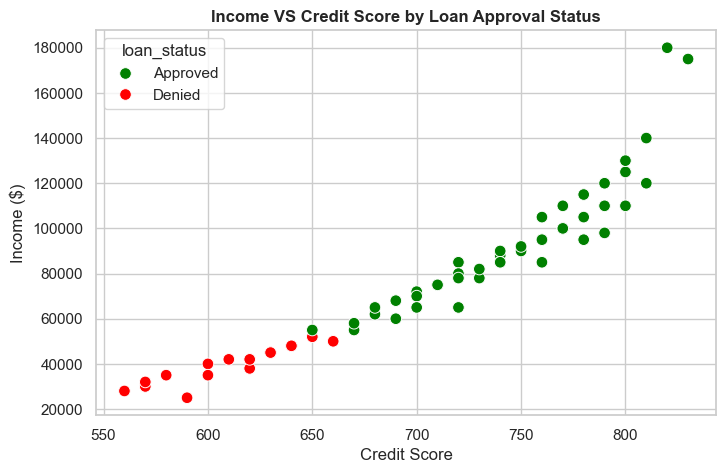

In [94]:
#set a clean grid style 
sns.set_theme(style='whitegrid')

#create scatter plot 
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x='credit_score',
    y='income',
    hue='loan_status',
    palette={'Approved': 'green' , 'Denied': 'red'},
    s=70
)
    #add titles and labels 
plt.title('Income VS Credit Score by Loan Approval Status' , fontsize=12, fontweight='bold')
plt.xlabel('Credit Score')
plt.ylabel('Income ($)')

#show plot
plt.show

Task 14: Build a Count Plot for Categorical Data
See the exact count of approved vs. denied loans across different education_level categories.

<function matplotlib.pyplot.show(close=None, block=None)>

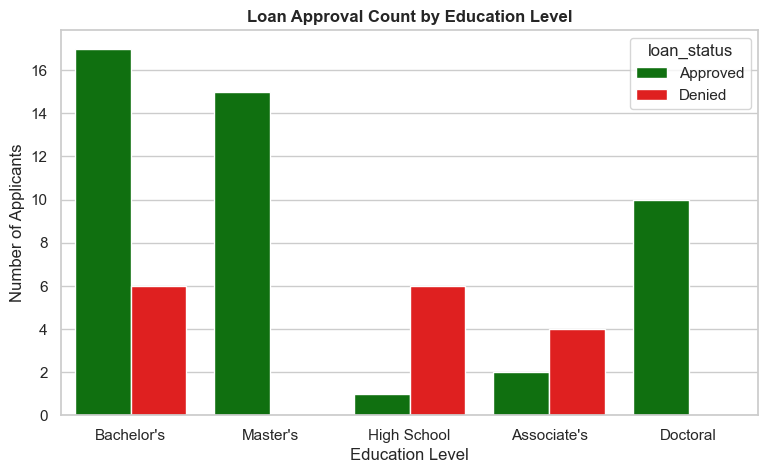

In [95]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df , 
    x='education_level',
    hue='loan_status' ,
    palette={'Approved': 'green', 'Denied': 'red'}
)

plt.title('Loan Approval Count by Education Level', fontsize=12, fontweight='bold')
plt.xlabel('Education Level')
plt.ylabel('Number of Applicants')

plt.show

Task 15: Create a Box Plot to Spot Income Distributions & Outliers
Box plots show you the median, quartiles (25th to 75th percentile), and extreme values (outliers) across categories.

/var/folders/fq/9qy812xn7z547ky1vc23p40w0000gn/T/ipykernel_42780/1711632909.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


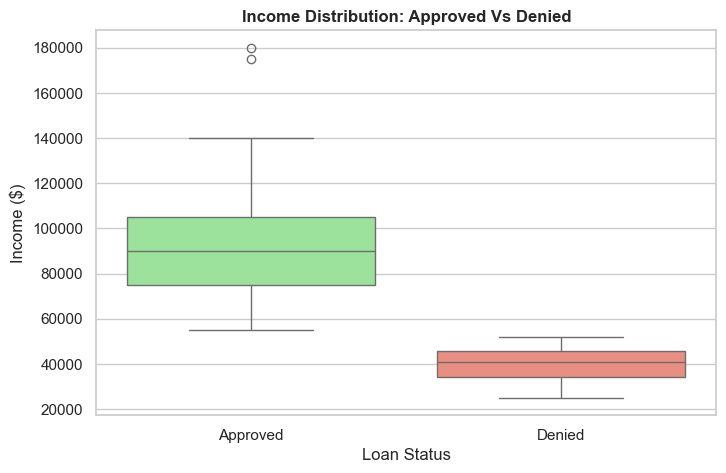

In [96]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df , 
    x='loan_status',
    y='income',
    palette={'Approved': 'lightgreen', 'Denied': 'salmon'} 

)

plt.title('Income Distribution: Approved Vs Denied', fontsize=12, fontweight='bold')
plt.xlabel('Loan Status')
plt.ylabel('Income ($)')

plt.show()

Task 16: Plot Your Engineered risk_tier Column
Visualize how your engineered risk_tier column (from Level 3) compares against actual loan approvals.

<function matplotlib.pyplot.show(close=None, block=None)>

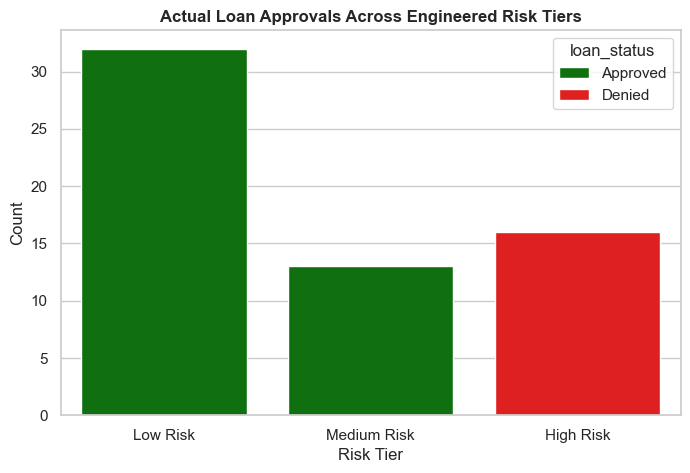

In [97]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x='risk_tier',
    hue='loan_status',
    order=['Low Risk', 'Medium Risk', 'High Risk'],
    palette={'Approved': 'green', 'Denied': 'red'}
)

plt.title('Actual Loan Approvals Across Engineered Risk Tiers', fontsize=12, fontweight='bold')
plt.xlabel('Risk Tier')
plt.ylabel('Count')

plt.show

Task 17: Prepare Features ($X$) and Target ($y$)Separating your predictor columns from the target column (loan_status) and converting categorical strings into numbers using One-Hot Encoding (pd.get_dummies()).

In [98]:
from sklearn.model_selection import train_test_split

In [99]:
#select numerical and categorical features 
features = ['age', 'gender', 'education_level', 'marital_status','income', 'credit_score']
X = df[features]

#convert categorical text columns into 1s and 0s 
X_encoded = pd.get_dummies(X, drop_first=True)

#create target vector y (1 for approved and 0 for denied)
y = df['loan_status'].apply(lambda x: 1 if x == 'Approved' else 0)

#display shape of transformed features 
print("Feature Matrix Shape:", X_encoded.shape)
print("Target Vector Shape:" ,y.shape)

Feature Matrix Shape: (61, 9)
Target Vector Shape: (61,)


Task 18: Train a Decision Tree Classifier
Instantiate a DecisionTreeClassifier and fit it on your dataset.

In [100]:
from sklearn.tree import DecisionTreeClassifier

#Initialize model (setting max_depth to keep rules simple and interpretable )
clf = DecisionTreeClassifier(max_depth=3, random_state=42)

#train the mode on the encoded data 
clf.fit(X_encoded, y)

print("Model Training Complete!")

Model Training Complete!


Task 19: Evaluate Model Accuracy & Print Classification MetricsCheck how well your model predicts loan approvals using a Confusion Matrix and a Classification Report ($Precision$, $Recall$, $F_1$-Score).

In [102]:
from sklearn.metrics import classification_report, confusion_matrix

#Make predicictions on the dataset 
y_pred = clf.predict(X_encoded)

#print confusion matrix
print("--- Confusion Matrix ---")
print(confusion_matrix(y, y_pred))

#print classification report 
print("\n--- Classification Report ---- ")
print(classification_report(y, y_pred, target_names= ['Denied (0)','Approved (1)']))

--- Confusion Matrix ---
[[16  0]
 [ 0 45]]

--- Classification Report ---- 
              precision    recall  f1-score   support

  Denied (0)       1.00      1.00      1.00        16
Approved (1)       1.00      1.00      1.00        45

    accuracy                           1.00        61
   macro avg       1.00      1.00      1.00        61
weighted avg       1.00      1.00      1.00        61



Task 20: Feature Importance Analysis & Plotting the Tree
Check which columns the Decision Tree relied on most to make its lending decisions, and display the tree structure.

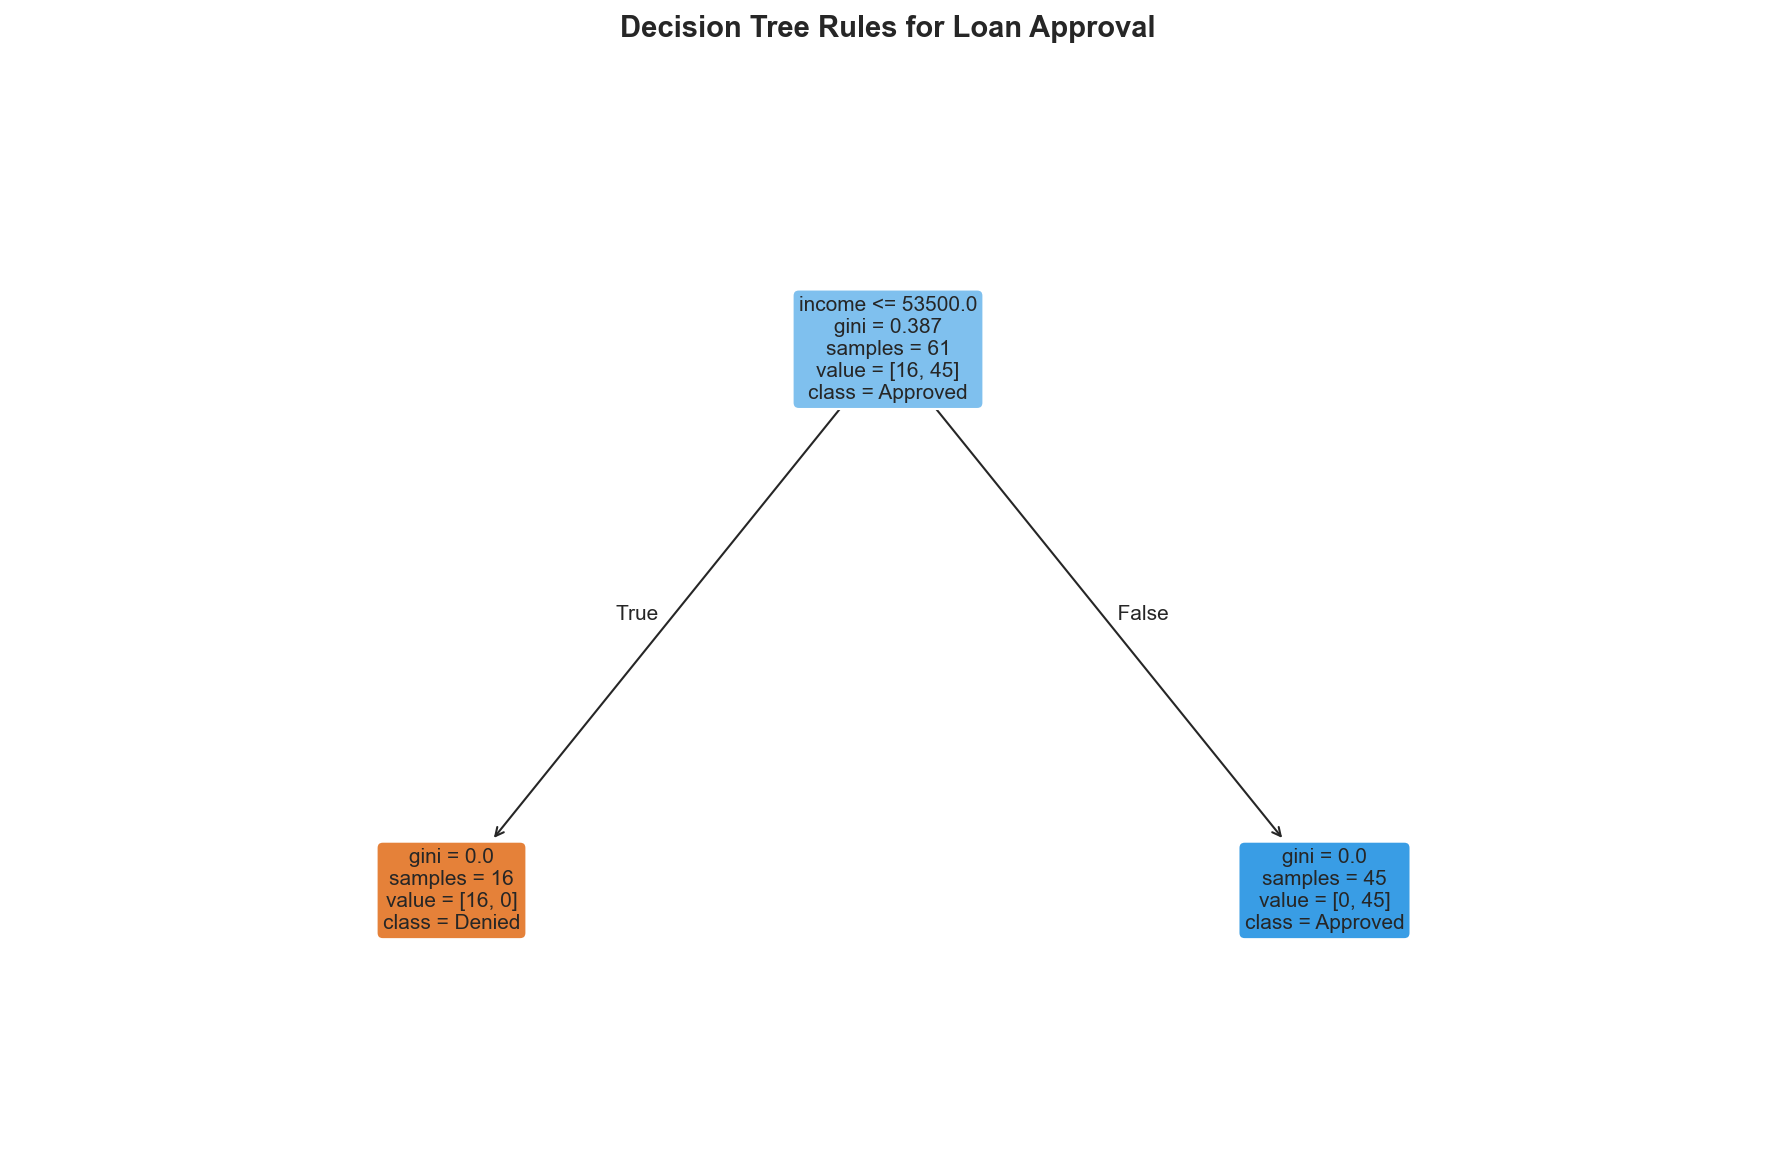

In [117]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree


plt.figure(figsize=(12, 8), dpi=150)

plot_tree(
    clf, 
    feature_names=X_encoded.columns, 
    class_names=['Denied', 'Approved'], 
    filled=True, 
    rounded=True,
    fontsize=10  
)

plt.title('Decision Tree Rules for Loan Approval', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()